In [1]:
import sys
from pathlib import Path

package_root = str(Path.cwd().parent)
if package_root not in sys.path:
    sys.path.append(package_root)

In [2]:
import pandas as pd 
from typing import Dict, List, Tuple
from pathlib import Path
from scipy.stats import skew, kurtosis
from package import training_and_evaluation
from collections.abc import Iterable
import matplotlib.pyplot as plt
import seaborn as sns
import os 
import time
import re
import numpy as np
from copy import deepcopy
from datetime import datetime

In [3]:
DATASET_FOLDER = "../../../dataset/processed-data"
DEVICE_MAPPING_FOLDER = DATASET_FOLDER + "/device-mapping"
INPUT_FOLDER = DATASET_FOLDER + "/input-data"
DATASET1 = "dataset1"
DATASET2 = "dataset2"

In [4]:
MAPPING_LIST_1 = f"{DEVICE_MAPPING_FOLDER}/{DATASET1}/list_of_devices_processed.csv"
MAPPING_LIST_2 = f"{DEVICE_MAPPING_FOLDER}/{DATASET2}/list_of_devices_processed.csv"
INPUT_1 = f"{INPUT_FOLDER}/{DATASET1}"
INPUT_2 = f"{INPUT_FOLDER}/{DATASET2}"

In [5]:
csv_files_1 = [f"{INPUT_1}/{f.name}" for f in sorted(Path(INPUT_1).iterdir()) if f.is_file() and f.suffix == ".csv"]
for file in csv_files_1:
    print(file)

../../../dataset/processed-data/input-data/dataset1/16-09-23.csv
../../../dataset/processed-data/input-data/dataset1/16-09-24.csv
../../../dataset/processed-data/input-data/dataset1/16-09-25.csv
../../../dataset/processed-data/input-data/dataset1/16-09-26.csv
../../../dataset/processed-data/input-data/dataset1/16-09-27.csv
../../../dataset/processed-data/input-data/dataset1/16-09-28.csv
../../../dataset/processed-data/input-data/dataset1/16-09-29.csv
../../../dataset/processed-data/input-data/dataset1/16-09-30.csv
../../../dataset/processed-data/input-data/dataset1/16-10-01.csv
../../../dataset/processed-data/input-data/dataset1/16-10-02.csv
../../../dataset/processed-data/input-data/dataset1/16-10-03.csv
../../../dataset/processed-data/input-data/dataset1/16-10-04.csv
../../../dataset/processed-data/input-data/dataset1/16-10-05.csv
../../../dataset/processed-data/input-data/dataset1/16-10-06.csv
../../../dataset/processed-data/input-data/dataset1/16-10-07.csv
../../../dataset/processe

In [6]:
device_mapping_1 = pd.read_csv(MAPPING_LIST_1)
device_dict_1 = (
    device_mapping_1
    .set_index("mac_address")
    .drop(columns=["mac_address"], errors="ignore")
    .to_dict(orient="index")
)
device_dict_1

{'d0:52:a8:00:67:5e': {'device_name': 'Smart Things',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'hub',
  'vendor': 'Samsung SmartThings'},
 '44:65:0d:56:cc:d3': {'device_name': 'Amazon Echo',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'smart speaker',
  'vendor': 'Amazon'},
 '70:ee:50:18:34:43': {'device_name': 'Netatmo Welcome',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'Netatmo'},
 'f4:f2:6d:93:51:f1': {'device_name': 'TP-Link Day Night Cloud camera',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'TP-Link'},
 '00:16:6c:ab:6b:88': {'device_name': 'Samsung SmartCam',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'Samsung'},
 '30:8c:fb:2f:e4:b2': {'device_name': 'Dropcam',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'Dropcam'},
 '00:62:6e:51:27:2e': {'device_name': 'Insteon Camera',
  'ip_address': nan,
 

# Feature Set 1 - Packet Count and Total Size
- For this experiment, I will be testing only feature `packet count`, and `total size`
- We'll experiment different window size
- We'll be using fixed WINDOW size for this experiment

In [7]:
def calculate_features(file_paths: Iterable[str], window: int) -> Tuple[pd.DataFrame, float]:
    columns = ["frame.time_epoch", "frame.len", "eth.src"]
    all_features = []

    startTime = time.perf_counter()
    for file_path in file_paths:
        df = pd.read_csv(
            file_path,
            usecols=columns,
            dtype={
                "frame.time_epoch": "float64",
                "frame.len": "int32",
                "eth.src": "category"
            },
        )
        start = df["frame.time_epoch"].min()

        df["window"] = (
            (df["frame.time_epoch"] - start) // window
        ).astype("int32")

        grouped = df.groupby(
            ["window", "eth.src"],
            sort=False,
            observed=True,
        )["frame.len"]

        basic_features = grouped.agg(
            packet_count="size",
            total_bytes="sum",
        ).reset_index()
        all_features.append(basic_features)
    endTime = time.perf_counter()

    return pd.concat(all_features, ignore_index=True), endTime - startTime


In [8]:
def label_features(features: pd.DataFrame, device_mapping: Dict[str, Dict[str, str]]) -> pd.DataFrame:
    # Check if eth.src is in device_mapping, and get label is_iot_device, device_type, and vendor
    features["is_iot_device"] = features["eth.src"].apply(
        lambda x: device_mapping.get(x, {}).get("is_iot_device", 0)
    )
    features["device_type"] = features["eth.src"].apply(
        lambda x: device_mapping.get(x, {}).get("device_type", "unknown")
    )
    features["vendor"] = features["eth.src"].apply(
        lambda x: device_mapping.get(x, {}).get("vendor", "unknown")
    )
    return features
    

In [ ]:
minWindow, maxWindow = 1, 300

In [ ]:
metrics = {}
feature_calculate_metric = {}
training_features = ["packet_count", "total_bytes"]
label = "is_iot_device"
for window in range(minWindow, maxWindow + 1):
    print(f"------------WINDOW: {window}-------------")
    features, time_taken = calculate_features(csv_files_1, window)
    feature_calculate_metric[window] = time_taken
    labeled_dataset = label_features(features, device_dict_1)
    X, y = labeled_dataset[training_features], labeled_dataset[label]
    experiment_results = training_and_evaluation(X, y)
    metrics[window] = experiment_results
    print(f"------------------------------------------")


In [ ]:
metric_copy = deepcopy(metrics)
combined_df = pd.concat(
    [
        df.assign(window=window)
        for window, df in metric_copy.items()
    ],
    ignore_index=True,
)
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
filename = f"combined_results_{timestamp}.csv"

combined_df.to_csv(filename, index=False)

## Performance Plotting

In [ ]:
x = sorted(feature_calculate_metric.keys())
y = [feature_calculate_metric[k] for k in x]

plt.figure(figsize=(15, 5))
plt.plot(x, y, marker="o")
plt.title("Feature Calculation Time vs Time Window")
plt.xlabel("Time Window")
plt.ylabel("Time Taken (seconds)")
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
def plot_results(
    combined_results: pd.DataFrame,
    output_dir: str = "result_plots",
) -> None:
    """
    For every (model, sample_method) pair, generate:
      1. Average accuracy by window, with min/max error bars
      2. Average train time by window, with min/max error bars
    """
    required_columns = {
        "model",
        "sample_method",
        "window",
        "accuracy",
        "train_time",
    }

    missing = required_columns - set(combined_results.columns)
    if missing:
        raise ValueError(f"Missing columns: {sorted(missing)}")

    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    output_path = Path(f"{output_dir}-{timestamp}")
    output_path.mkdir(parents=True, exist_ok=True)

    # Ensure numeric columns are interpreted correctly.
    df = combined_results.copy()
    df["window"] = pd.to_numeric(df["window"], errors="coerce")
    df["accuracy"] = pd.to_numeric(df["accuracy"], errors="coerce")
    df["train_time"] = pd.to_numeric(df["train_time"], errors="coerce")

    df = df.dropna(
        subset=["model", "sample_method", "window", "accuracy", "train_time"]
    )

    grouped = (
        df.groupby(
            ["model", "sample_method", "window"],
            observed=True,
            sort=True,
        )
        .agg(
            accuracy_mean=("accuracy", "mean"),
            accuracy_min=("accuracy", "min"),
            accuracy_max=("accuracy", "max"),
            train_time_mean=("train_time", "mean"),
            train_time_min=("train_time", "min"),
            train_time_max=("train_time", "max"),
        )
        .reset_index()
    )

    for (model, sample_method), pair_df in grouped.groupby(
        ["model", "sample_method"],
        observed=True,
        sort=False,
    ):
        pair_df = pair_df.sort_values("window")

        safe_name = re.sub(
            r"[^A-Za-z0-9_-]+",
            "_",
            f"{model}_{sample_method}",
        )

        # -------------------------
        # Accuracy plot
        # -------------------------
        mean = pair_df["accuracy_mean"]

        plt.figure(figsize=(16, 5))

        plt.errorbar(
            pair_df["window"],
            mean,
            yerr=[
                mean - pair_df["accuracy_min"],
                pair_df["accuracy_max"] - mean,
            ],
            marker="o",
            markersize=4,
            linewidth=1.5,
            capsize=4,
            label="Mean with min/max",
        )

        plt.title(f"Accuracy vs Window\n{model} — {sample_method}")
        plt.xlabel("Window")
        plt.ylabel("Accuracy")
        plt.grid(alpha=0.3)
        plt.legend()
        plt.tight_layout()

        plt.savefig(
            output_path / f"{safe_name}_accuracy.png",
            dpi=300,
            bbox_inches="tight",
        )
        plt.show()
        plt.close()

        # -------------------------
        # Training-time plot
        # -------------------------
        mean = pair_df["train_time_mean"]

        plt.figure(figsize=(16, 5))

        plt.errorbar(
            pair_df["window"],
            mean,
            yerr=[
                mean - pair_df["train_time_min"],
                pair_df["train_time_max"] - mean,
            ],
            marker="o",
            markersize=4,
            linewidth=1.5,
            capsize=4,
            label="Mean with min/max",
        )

        plt.title(f"Training Time vs Window\n{model} — {sample_method}")
        plt.xlabel("Window")
        plt.ylabel("Training Time (seconds)")
        plt.grid(alpha=0.3)
        plt.legend()
        plt.tight_layout()

        plt.savefig(
            output_path / f"{safe_name}_train_time.png",
            dpi=300,
            bbox_inches="tight",
        )
        plt.show()
        plt.close()

In [ ]:
plot_results(combined_df, output_dir="performance-plot")

- Trying out diffferent model and sampling method, window size ranging from 4 to 9 seconds is the best time window given this dataset

## Check for different type of WINDOW calculation
- In this experiment, we will be testing if scrolling window give us better accuracy. The time window range we will be using is from 4 to 9 seconds for both type of window:
    - Fixed window
    - Sliding window

In [ ]:
MIN_OPTIMAL_WINDOW, MAX_OPTIMAL_WINDOW = 4, 9

In [ ]:
def calculate_features_sliding(
    file_paths: Iterable[str],
    window_size: float,
    step_size: float,
) -> Tuple[pd.DataFrame, float]:
    """
    Calculate packet-count and total-byte features using sliding windows.

    Windows are left-inclusive and right-exclusive:

        [window_start, window_start + window_size)

    For example, window_size=10 and step_size=2 produces:

        [0, 10), [2, 12), [4, 14), ...

    Parameters
    ----------
    file_paths:
        Paths to packet CSV files.

    window_size:
        Duration of each window in seconds.

    step_size:
        Distance between consecutive window starts in seconds.
        For overlapping windows, step_size must be smaller than window_size.

    Returns
    -------
    features:
        DataFrame containing:
        - source_file
        - window
        - window_start
        - window_end
        - eth.src
        - packet_count
        - total_bytes

    elapsed_time:
        Total execution time in seconds.
    """
    if window_size <= 0:
        raise ValueError("window_size must be greater than 0.")

    if step_size <= 0:
        raise ValueError("step_size must be greater than 0.")

    columns = ["frame.time_epoch", "frame.len", "eth.src"]
    all_features = []

    start_time = time.perf_counter()

    for file_path in file_paths:
        df = pd.read_csv(
            file_path,
            usecols=columns,
            dtype={
                "frame.time_epoch": "float64",
                "frame.len": "int32",
                "eth.src": "category",
            },
        )

        if df.empty:
            continue

        capture_start = df["frame.time_epoch"].min()
        capture_end = df["frame.time_epoch"].max()

        # Number of sliding-window start positions.
        number_of_windows = (
            int(np.floor((capture_end - capture_start) / step_size)) + 1
        )

        window_ids = np.arange(number_of_windows, dtype=np.int32)

        # Absolute timestamps used for searching packet positions.
        absolute_window_starts = (
            capture_start + window_ids.astype(np.float64) * step_size
        )
        absolute_window_ends = absolute_window_starts + window_size

        # Relative times are easier to interpret and compare between files.
        relative_window_starts = window_ids.astype(np.float64) * step_size
        relative_window_ends = relative_window_starts + window_size

        for mac, device_df in df.groupby(
            "eth.src",
            sort=False,
            observed=True,
        ):
            # searchsorted requires sorted timestamps.
            device_df = device_df.sort_values(
                "frame.time_epoch",
                kind="mergesort",
            )

            packet_times = device_df["frame.time_epoch"].to_numpy()
            packet_lengths = device_df["frame.len"].to_numpy(
                dtype=np.int64,
            )

            # Locate the packet range belonging to each window.
            left_indices = np.searchsorted(
                packet_times,
                absolute_window_starts,
                side="left",
            )

            right_indices = np.searchsorted(
                packet_times,
                absolute_window_ends,
                side="left",
            )

            packet_counts = right_indices - left_indices

            # Prefix sums allow total bytes to be calculated in O(1)
            # for each window after one cumulative-sum pass.
            cumulative_bytes = np.empty(
                len(packet_lengths) + 1,
                dtype=np.int64,
            )
            cumulative_bytes[0] = 0

            np.cumsum(
                packet_lengths,
                dtype=np.int64,
                out=cumulative_bytes[1:],
            )

            total_bytes = (
                cumulative_bytes[right_indices]
                - cumulative_bytes[left_indices]
            )

            # Preserve the original behavior: do not produce rows for
            # device-window combinations containing no packets.
            non_empty = packet_counts > 0

            if not np.any(non_empty):
                continue

            device_features = pd.DataFrame(
                {
                    "source_file": Path(file_path).name,
                    "window": window_ids[non_empty],
                    "window_start": relative_window_starts[non_empty],
                    "window_end": relative_window_ends[non_empty],
                    "eth.src": mac,
                    "packet_count": packet_counts[non_empty].astype(
                        np.int32
                    ),
                    "total_bytes": total_bytes[non_empty],
                }
            )

            all_features.append(device_features)

    if all_features:
        features = pd.concat(all_features, ignore_index=True)
    else:
        features = pd.DataFrame(
            columns=[
                "source_file",
                "window",
                "window_start",
                "window_end",
                "eth.src",
                "packet_count",
                "total_bytes",
            ]
        )

    elapsed_time = time.perf_counter() - start_time
    print(f"WINDOW: {window} - Computed {len(features):,} samples")

    return features, elapsed_time

In [ ]:
fixed_window_metrics = {}
feature_calculate_metric_2 = {}
training_features = ["packet_count", "total_bytes"]
label = "is_iot_device"
for window in range(MIN_OPTIMAL_WINDOW, MAX_OPTIMAL_WINDOW + 1):
    print(f"------------WINDOW: {window}-------------")
    features, time_taken = calculate_features(csv_files_1, window)
    feature_calculate_metric_2[window] = time_taken
    labeled_dataset = label_features(features, device_dict_1)
    X, y = labeled_dataset[training_features], labeled_dataset[label]
    experiment_results = training_and_evaluation(X, y)
    fixed_window_metrics[window] = experiment_results
    print(f"------------------------------------------")


In [ ]:
SLIDING_STEP = 2 # 2 seconds

In [ ]:
sliding_window_metrics = {}
sliding_feature_calculate_metric = {}
training_features = ["packet_count", "total_bytes"]
label = "is_iot_device"
for window in range(MIN_OPTIMAL_WINDOW, MAX_OPTIMAL_WINDOW + 1):
    print(f"------------WINDOW: {window}-------------")
    features, time_taken = calculate_features_sliding(csv_files_1, window, SLIDING_STEP)
    sliding_feature_calculate_metric[window] = time_taken
    labeled_dataset = label_features(features, device_dict_1)
    X, y = labeled_dataset[training_features], labeled_dataset[label]
    experiment_results = training_and_evaluation(X, y)
    sliding_window_metrics[window] = experiment_results
    print(f"------------------------------------------")


In [ ]:
# Tumbling-window metrics
tumbling_x = sorted(feature_calculate_metric_2.keys())
tumbling_y = [
    feature_calculate_metric_2[window]
    for window in tumbling_x
]

# Sliding-window metrics
sliding_x = sorted(sliding_feature_calculate_metric.keys())
sliding_y = [
    sliding_feature_calculate_metric[window]
    for window in sliding_x
]

plt.figure(figsize=(15, 5))

plt.plot(
    tumbling_x,
    tumbling_y,
    marker="o",
    label="Tumbling Window",
)

plt.plot(
    sliding_x,
    sliding_y,
    marker="o",
    label="Sliding Window",
)

plt.title("Feature Calculation Time vs Time Window")
plt.xlabel("Time Window (seconds)")
plt.ylabel("Time Taken (seconds)")
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
def plot_diff_window_results(
    tumbling_results: pd.DataFrame,
    sliding_results: pd.DataFrame,
    output_dir: str = "result_plots",
) -> None:
    """
    Compare tumbling-window and sliding-window results.

    For every (model, sample_method) pair, generate:
      1. Average accuracy by window, with min/max error bars
      2. Average training time by window, with min/max error bars

    Each plot contains separate lines for:
      - Tumbling Window
      - Sliding Window
    """
    required_columns = {
        "model",
        "sample_method",
        "window",
        "accuracy",
        "train_time",
    }

    # Validate both DataFrames.
    for dataframe_name, dataframe in [
        ("tumbling_results", tumbling_results),
        ("sliding_results", sliding_results),
    ]:
        missing = required_columns - set(dataframe.columns)

        if missing:
            raise ValueError(
                f"{dataframe_name} is missing columns: "
                f"{sorted(missing)}"
            )

    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    output_path = Path(f"{output_dir}-{timestamp}")
    output_path.mkdir(parents=True, exist_ok=True)

    # Add the window method so the two datasets can be distinguished.
    tumbling_df = tumbling_results.copy()
    tumbling_df["window_type"] = "Tumbling Window"

    sliding_df = sliding_results.copy()
    sliding_df["window_type"] = "Sliding Window"

    # Combine both experiment result sets.
    df = pd.concat(
        [tumbling_df, sliding_df],
        ignore_index=True,
    )

    # Ensure metric columns are numeric.
    numeric_columns = [
        "window",
        "accuracy",
        "train_time",
    ]

    for column in numeric_columns:
        df[column] = pd.to_numeric(
            df[column],
            errors="coerce",
        )

    df = df.dropna(
        subset=[
            "window_type",
            "model",
            "sample_method",
            "window",
            "accuracy",
            "train_time",
        ]
    )

    # Calculate mean, minimum, and maximum for each configuration.
    grouped = (
        df.groupby(
            [
                "window_type",
                "model",
                "sample_method",
                "window",
            ],
            observed=True,
            sort=True,
        )
        .agg(
            accuracy_mean=("accuracy", "mean"),
            accuracy_min=("accuracy", "min"),
            accuracy_max=("accuracy", "max"),
            train_time_mean=("train_time", "mean"),
            train_time_min=("train_time", "min"),
            train_time_max=("train_time", "max"),
        )
        .reset_index()
    )

    # Generate one pair of plots for every model and sampling method.
    for (model, sample_method), pair_df in grouped.groupby(
        ["model", "sample_method"],
        observed=True,
        sort=False,
    ):
        safe_name = re.sub(
            r"[^A-Za-z0-9_-]+",
            "_",
            f"{model}_{sample_method}",
        )

        # -------------------------------------------------
        # Accuracy plot
        # -------------------------------------------------
        plt.figure(figsize=(16, 5))

        for window_type, window_df in pair_df.groupby(
            "window_type",
            observed=True,
            sort=False,
        ):
            window_df = window_df.sort_values("window")
            mean = window_df["accuracy_mean"]

            plt.errorbar(
                window_df["window"],
                mean,
                yerr=[
                    mean - window_df["accuracy_min"],
                    window_df["accuracy_max"] - mean,
                ],
                marker="o",
                markersize=4,
                linewidth=1.5,
                capsize=4,
                label=window_type,
            )

        plt.title(
            f"Accuracy vs Window\n"
            f"{model} — {sample_method}"
        )
        plt.xlabel("Window Size (seconds)")
        plt.ylabel("Accuracy")
        plt.grid(alpha=0.3)
        plt.legend()
        plt.tight_layout()

        plt.savefig(
            output_path / f"{safe_name}_accuracy.png",
            dpi=300,
            bbox_inches="tight",
        )

        plt.show()
        plt.close()

        # -------------------------------------------------
        # Training-time plot
        # -------------------------------------------------
        plt.figure(figsize=(16, 5))

        for window_type, window_df in pair_df.groupby(
            "window_type",
            observed=True,
            sort=False,
        ):
            window_df = window_df.sort_values("window")
            mean = window_df["train_time_mean"]

            plt.errorbar(
                window_df["window"],
                mean,
                yerr=[
                    mean - window_df["train_time_min"],
                    window_df["train_time_max"] - mean,
                ],
                marker="o",
                markersize=4,
                linewidth=1.5,
                capsize=4,
                label=window_type,
            )

        plt.title(
            f"Training Time vs Window\n"
            f"{model} — {sample_method}"
        )
        plt.xlabel("Window Size (seconds)")
        plt.ylabel("Training Time (seconds)")
        plt.grid(alpha=0.3)
        plt.legend()
        plt.tight_layout()

        plt.savefig(
            output_path / f"{safe_name}_train_time.png",
            dpi=300,
            bbox_inches="tight",
        )

        plt.show()
        plt.close()

    print(f"Plots saved to: {output_path.resolve()}")

In [ ]:
tumbling_metric_copy = deepcopy(fixed_window_metrics)
tumbling_df = pd.concat(
    [
        df.assign(window=window)
        for window, df in tumbling_metric_copy.items()
    ],
    ignore_index=True,
)
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
filename = f"optimal_tumbling_window_{timestamp}.csv"

tumbling_df.to_csv(filename, index=False)

In [ ]:
tumbling_metric_copy = deepcopy(fixed_window_metrics)
tumbling_df = pd.concat(
    [
        df.assign(window=window)
        for window, df in tumbling_metric_copy.items()
    ],
    ignore_index=True,
)
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
filename = f"optimal_tumbling_window_{timestamp}.csv"

tumbling_df.to_csv(filename, index=False)

In [ ]:

sliding_metric_copy = deepcopy(sliding_window_metrics)
sliding_df = pd.concat(
    [
        df.assign(window=window)
        for window, df in sliding_metric_copy.items()
    ],
    ignore_index=True,
)
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
filename = f"optimal_sliding_window_{timestamp}.csv"

sliding_df.to_csv(filename, index=False)

In [ ]:
plot_diff_window_results(tumbling_df, sliding_df, output_dir="tumbling_vs_sliding")

## Figure out why the accuracy can only reach 97%
- I will use the window = 4 because it seems to be the one that has highest accuracy

In [12]:
DEBUG_WINDOW = 5

In [13]:
from imblearn.under_sampling import RandomUnderSampler
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler


def create_under_sampler(random_seed: int = 42) -> RandomUnderSampler:
    """
    Create a RandomUnderSampler for undersampling the majority class.

    Args:
        random_seed (int): Random seed for reproducibility.

    Returns:
        RandomUnderSampler: An instance of the RandomUnderSampler.
    """
    return RandomUnderSampler(random_state=random_seed)

def create_decision_tree(random_seed: int = 42) -> DecisionTreeClassifier:
    return DecisionTreeClassifier(
        criterion="gini",
        splitter="best",
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        min_weight_fraction_leaf=0.0,
        max_features=None,
        max_leaf_nodes=None,
        min_impurity_decrease=0.0,
        class_weight=None,
        random_state=random_seed,
    )

stratifiedKFold = StratifiedKFold(n_splits=5)

In [117]:
features, _ = calculate_features(csv_files_1, DEBUG_WINDOW)
labeled_dataset = label_features(features, device_dict_1)

In [118]:
labeled_dataset = labeled_dataset[labeled_dataset["packet_count"] >= 4].copy()

In [119]:
label = "is_iot_device"
training_feature = ["total_bytes", "packet_count"]
all_features = [feature for feature in features.columns if feature != label and feature != "window"]

In [120]:
X, y = labeled_dataset[all_features], labeled_dataset[label]

In [121]:
X.head(10)

,eth.src,packet_count,total_bytes,device_type,vendor
1,14:cc:20:51:33:ea,21,1680,unknown,unknown
5,30:8c:fb:2f:e4:b2,5,780,camera,Dropcam
11,14:cc:20:51:33:ea,6,372,unknown,unknown
12,00:16:6c:ab:6b:88,38,14497,camera,Samsung
13,ec:1a:59:83:28:11,101,10097,motion sensor,Belkin
14,ec:1a:59:79:f4:89,85,23949,smart switch,Belkin
16,30:8c:fb:2f:e4:b2,4,624,camera,Dropcam
19,14:cc:20:51:33:ea,8,590,unknown,unknown
20,30:8c:fb:2f:e4:b2,4,534,camera,Dropcam
23,30:8c:fb:2f:e4:b2,5,780,camera,Dropcam


- Label count and device count before sampling

In [122]:
display(X.groupby(["eth.src", "device_type"]).count().sort_values(by="device_type"))
display(y.value_counts())

,,packet_count,total_bytes,vendor
eth.src,device_type,,,
00:24:e4:11:18:a8,baby monitor,5329,5329,5329
74:6a:89:00:2e:25,blood pressure monitor,10,10,10
00:16:6c:ab:6b:88,camera,79106,79106,79106
00:62:6e:51:27:2e,camera,45505,45505,45505
30:8c:fb:2f:e4:b2,camera,308099,308099,308099
30:8c:fb:b6:ea:45,camera,390,390,390
70:ee:50:18:34:43,camera,7404,7404,7404
e8:ab:fa:19:de:4f,camera,43,43,43
f4:f2:6d:93:51:f1,camera,2522,2522,2522


is_iot_device
1    551513
0    373862
Name: count, dtype: int64

- Label count and device count after sampling

In [123]:
training_and_validation_set = []
for iteration, (train_indices, val_indices) in enumerate(stratifiedKFold.split(X=X, y=y)):
    X_train, y_train = X.iloc[train_indices].reset_index(drop=True), y.iloc[train_indices].reset_index(drop=True)
    X_val, y_val = X.iloc[val_indices].reset_index(drop=True), y.iloc[val_indices].reset_index(drop=True)
    sampler = create_under_sampler()

    X_sample, y_sample = sampler.fit_resample(X_train, y_train)
    print(f"Iteration: {iteration}")
    display(X_sample.groupby(["eth.src", "device_type"]).count().sort_values(by="device_type"))
    display(y_sample.value_counts())

    training_and_validation_set.append((X_sample, y_sample, X_val, y_val))


Iteration: 0


,,packet_count,total_bytes,vendor
eth.src,device_type,,,
00:24:e4:11:18:a8,baby monitor,2668,2668,2668
74:6a:89:00:2e:25,blood pressure monitor,6,6,6
00:16:6c:ab:6b:88,camera,42159,42159,42159
00:62:6e:51:27:2e,camera,30778,30778,30778
30:8c:fb:2f:e4:b2,camera,162582,162582,162582
30:8c:fb:b6:ea:45,camera,278,278,278
70:ee:50:18:34:43,camera,4021,4021,4021
e8:ab:fa:19:de:4f,camera,31,31,31
f4:f2:6d:93:51:f1,camera,1244,1244,1244


is_iot_device
0    299089
1    299089
Name: count, dtype: int64

Iteration: 1


,,packet_count,total_bytes,vendor
eth.src,device_type,,,
00:24:e4:11:18:a8,baby monitor,2617,2617,2617
74:6a:89:00:2e:25,blood pressure monitor,3,3,3
00:16:6c:ab:6b:88,camera,43166,43166,43166
00:62:6e:51:27:2e,camera,24035,24035,24035
30:8c:fb:2f:e4:b2,camera,167222,167222,167222
30:8c:fb:b6:ea:45,camera,278,278,278
70:ee:50:18:34:43,camera,3729,3729,3729
f4:f2:6d:93:51:f1,camera,1020,1020,1020
d0:52:a8:00:67:5e,hub,2931,2931,2931


is_iot_device
0    299089
1    299089
Name: count, dtype: int64

... (5 outputs left out)

is_iot_device
0    299090
1    299090
Name: count, dtype: int64

Iteration: 4


,,packet_count,total_bytes,vendor
eth.src,device_type,,,
00:24:e4:11:18:a8,baby monitor,3588,3588,3588
74:6a:89:00:2e:25,blood pressure monitor,4,4,4
00:16:6c:ab:6b:88,camera,42720,42720,42720
00:62:6e:51:27:2e,camera,22170,22170,22170
30:8c:fb:2f:e4:b2,camera,168476,168476,168476
30:8c:fb:b6:ea:45,camera,253,253,253
70:ee:50:18:34:43,camera,4281,4281,4281
e8:ab:fa:19:de:4f,camera,32,32,32
f4:f2:6d:93:51:f1,camera,1720,1720,1720


is_iot_device
0    299090
1    299090
Name: count, dtype: int64

In [124]:
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score
from numpy.typing import NDArray
def custom_evaluation(y_pred: pd.DataFrame, y_true: pd.DataFrame, X_val: pd.DataFrame, labels: NDArray) -> Dict[str, float]:
    precisions = precision_score(y_true=y_true, y_pred=y_pred, labels=labels, average=None)
    recalls = recall_score(y_true=y_true, y_pred=y_pred, labels=labels, average=None)
    f1_scores = f1_score(y_true=y_true, y_pred=y_pred, labels=labels, average=None)
    accuracy = accuracy_score(y_true=y_true, y_pred=y_pred)

    metric_dict = {"accuracy": accuracy}
    for index, label in enumerate(labels):
        metric_dict[f"precision_class_{label}"] = precisions[index]
        metric_dict[f"recall_class_{label}"] = recalls[index]
        metric_dict[f"f1_class_{label}"] = f1_scores[index]

    y_true_array = np.asarray(y_true)
    y_pred_array = np.asarray(y_pred)

    false_positive_positions = np.flatnonzero(
        (y_true_array == 0) & (y_pred_array == 1)
    )

    false_negative_positions = np.flatnonzero(
        (y_true_array == 1) & (y_pred_array == 0)
    )

    false_positive_samples = X_val.iloc[false_positive_positions]
    false_negative_samples = X_val.iloc[false_negative_positions]

    fp_dict = (
        false_positive_samples
        .groupby(["eth.src", "device_type"], observed=True)
        .size()
        .to_dict()
    )

    fn_dict = (
        false_negative_samples
        .groupby(["eth.src", "device_type"], observed=True)
        .size()
        .to_dict()
    )

    metric_dict["false_positives"] = fp_dict
    metric_dict["false_negatives"] = fn_dict
        
    return metric_dict

In [125]:
metrics = []
for iteration, (X_sample, y_sample, X_val, y_val) in enumerate(training_and_validation_set):
    print(f"Iteration: {iteration}.......")
    scaler = StandardScaler()
    model = create_decision_tree()
    X_sample_train = X_sample[training_feature]
    X_val_test = X_val[training_feature]

    X_sample_train = scaler.fit_transform(X_sample_train)
    X_val_test = scaler.transform(X_val_test)

    model.fit(X_sample_train, y_sample)
    y_pred = model.predict(X_val_test)

    metric_dict = custom_evaluation(y_pred, y_val, X_val, np.unique(y_val))
    metric_dict["iteration"] = iteration
    metrics.append(metric_dict)

Iteration: 0.......
Iteration: 1.......
Iteration: 2.......
Iteration: 3.......
Iteration: 4.......


In [126]:
metric_df = pd.DataFrame(metrics)

In [127]:
metric_df

,accuracy,precision_class_0,recall_class_0,f1_class_0,precision_class_1,recall_class_1,f1_class_1,false_positives,false_negatives,iteration
0,0.929056,0.880188,0.954302,0.915748,0.967146,0.911942,0.938733,"{('08:21:ef:3b:fc:e3', 'unknown'): 275, ('14:c...","{('00:16:6c:ab:6b:88', 'camera'): 2605, ('00:2...",0
1,0.958325,0.929003,0.971059,0.949565,0.979760,0.949693,0.964492,"{('08:21:ef:3b:fc:e3', 'unknown'): 362, ('14:c...","{('00:16:6c:ab:6b:88', 'camera'): 540, ('00:24...",1
2,0.964809,0.943488,0.971059,0.957075,0.979985,0.960572,0.970181,"{('08:21:ef:3b:fc:e3', 'unknown'): 420, ('14:c...","{('00:16:6c:ab:6b:88', 'camera'): 223, ('00:24...",2
3,0.943925,0.920469,0.942652,0.931429,0.960480,0.944788,0.952569,"{('00:24:e4:10:ee:4c', 'unknown'): 24, ('08:21...","{('00:16:6c:ab:6b:88', 'camera'): 1175, ('00:2...",3
4,0.956007,0.948216,0.942585,0.945392,0.961236,0.965105,0.963167,"{('08:21:ef:3b:fc:e3', 'unknown'): 537, ('14:c...","{('00:16:6c:ab:6b:88', 'camera'): 512, ('00:24...",4


In [128]:
def plot_errors_by_iteration(metric_df: pd.DataFrame) -> None:
    for _, row in metric_df.iterrows():
        iteration = row["iteration"]

        for column, title in [
            ("false_positives", "False Positives"),
            ("false_negatives", "False Negatives"),
        ]:
            error_dict = row[column]

            plot_df = pd.DataFrame(
                [
                    {
                        "category": f"{eth_src}\n{device_type}",
                        "count": count,
                    }
                    for (eth_src, device_type), count in error_dict.items()
                ]
            ).sort_values("count", ascending=False)

            ax = plot_df.plot(
                x="category",
                y="count",
                kind="bar",
                figsize=(14, 6),
                legend=False,
            )

            ax.set_title(f"{title} — Iteration {iteration}")
            ax.set_xlabel("(eth.src, device_type)")
            ax.set_ylabel("Count")
            ax.tick_params(axis="x", rotation=45)

            plt.tight_layout()
            plt.show()

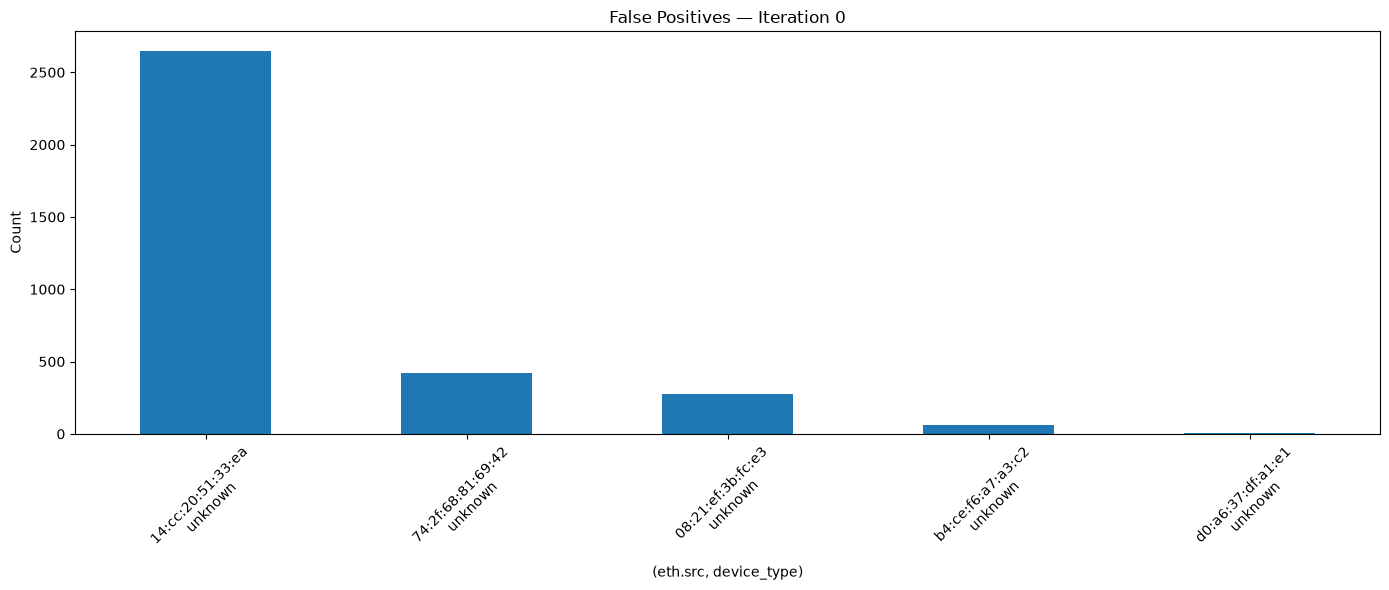

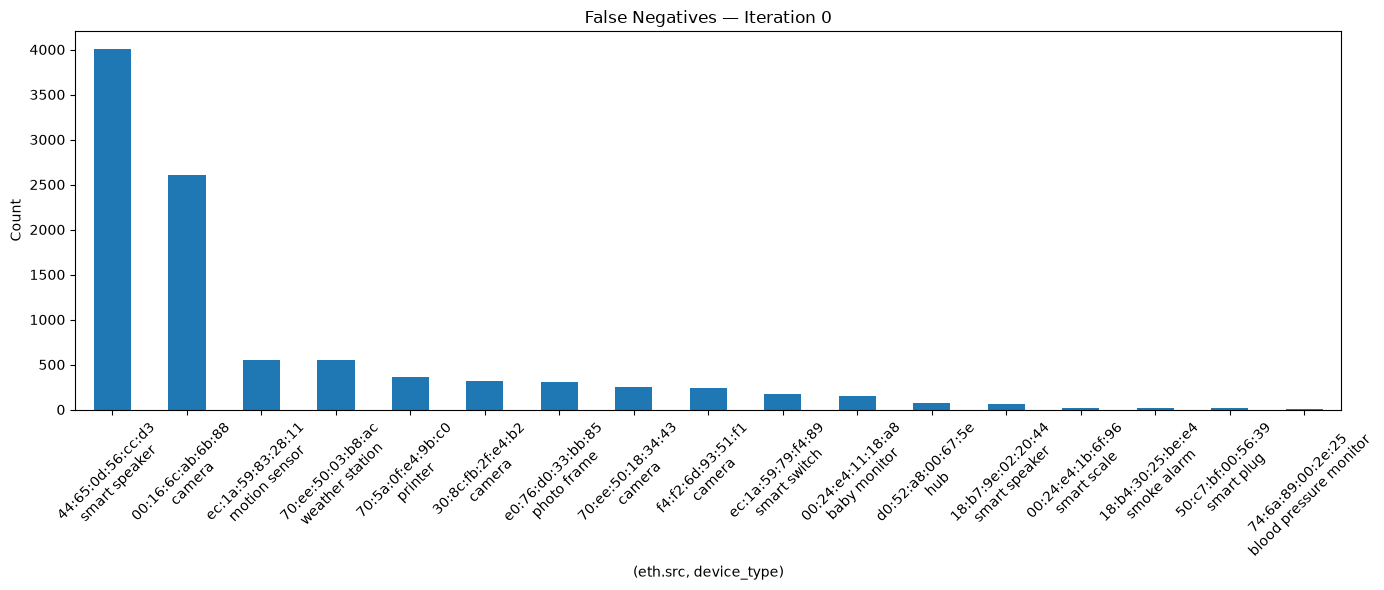

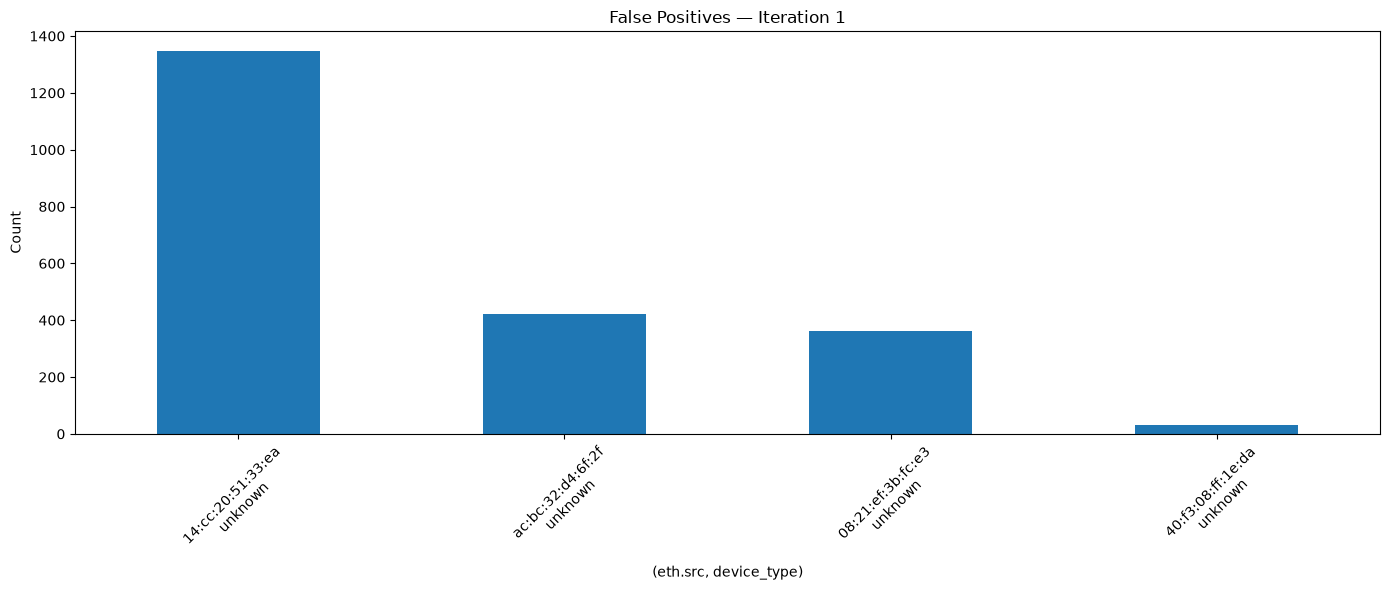

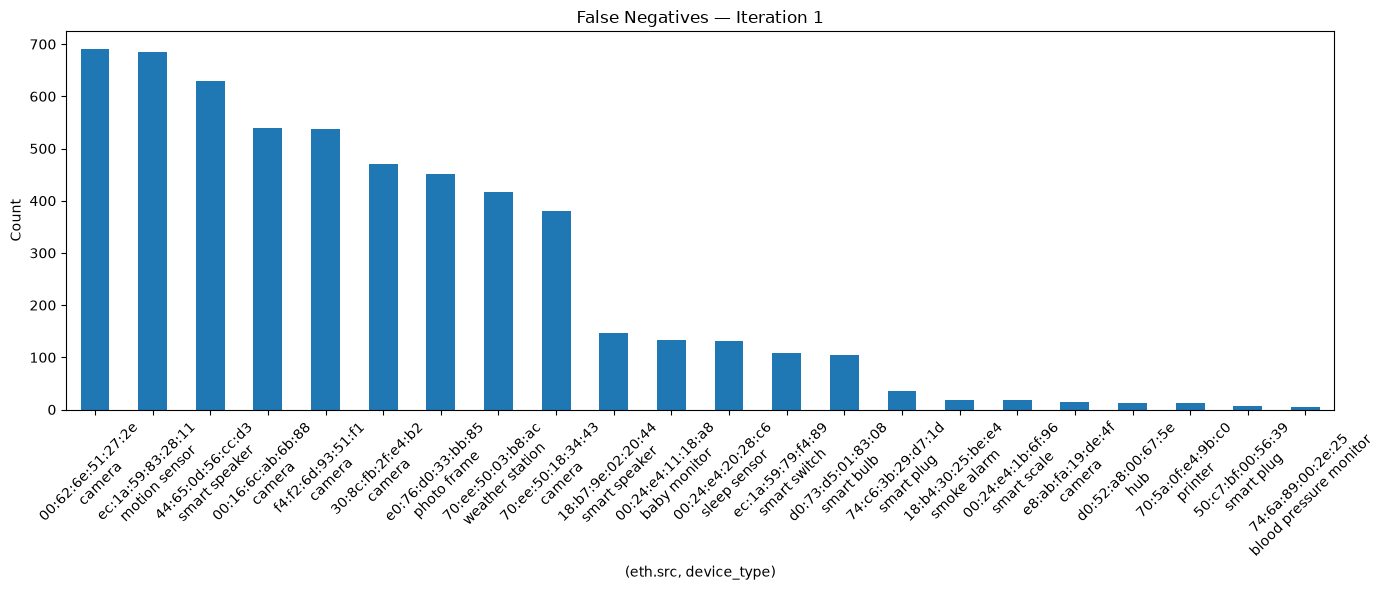

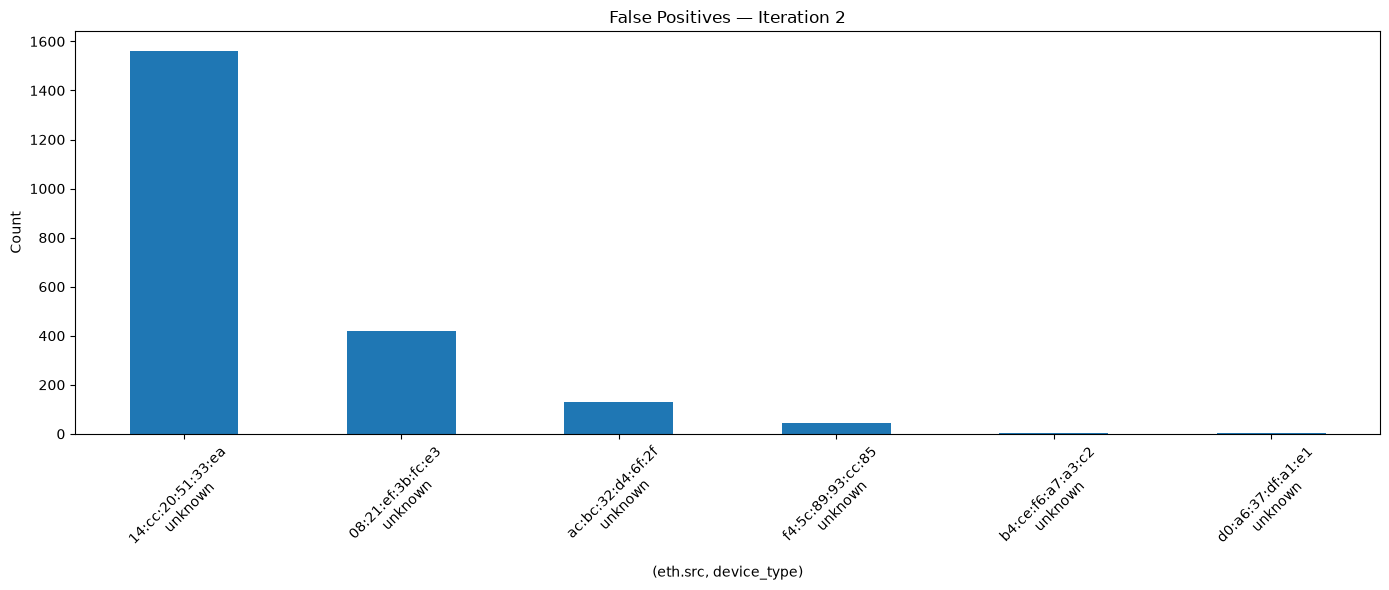

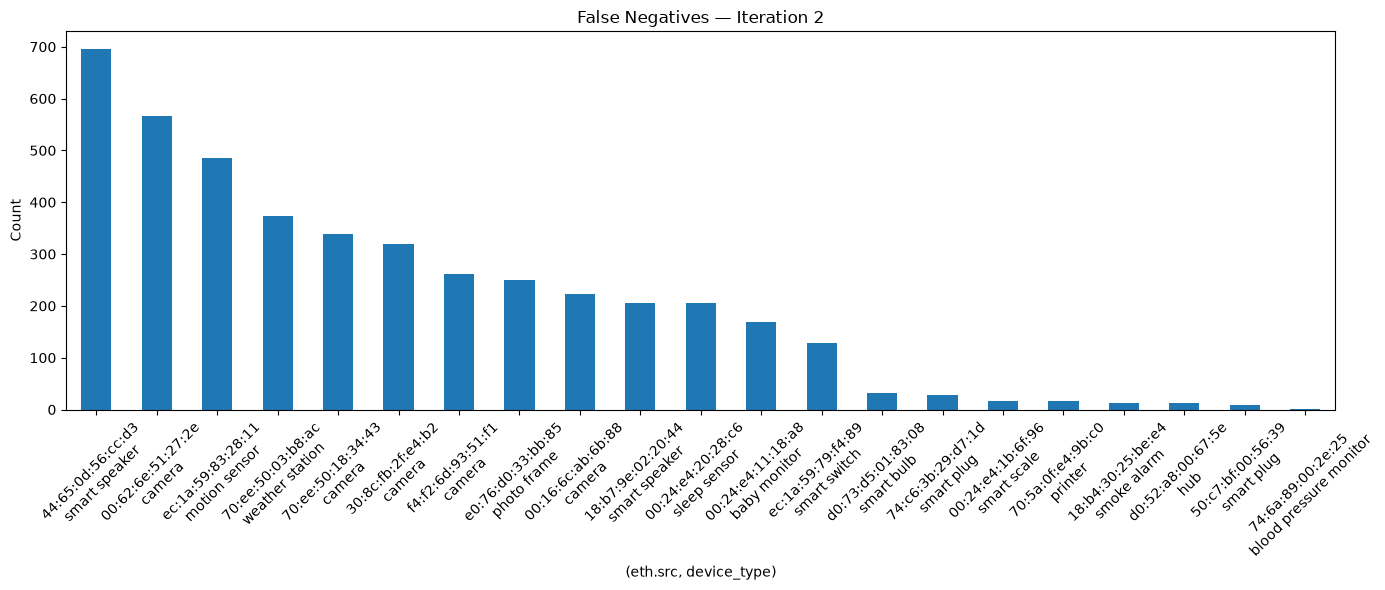

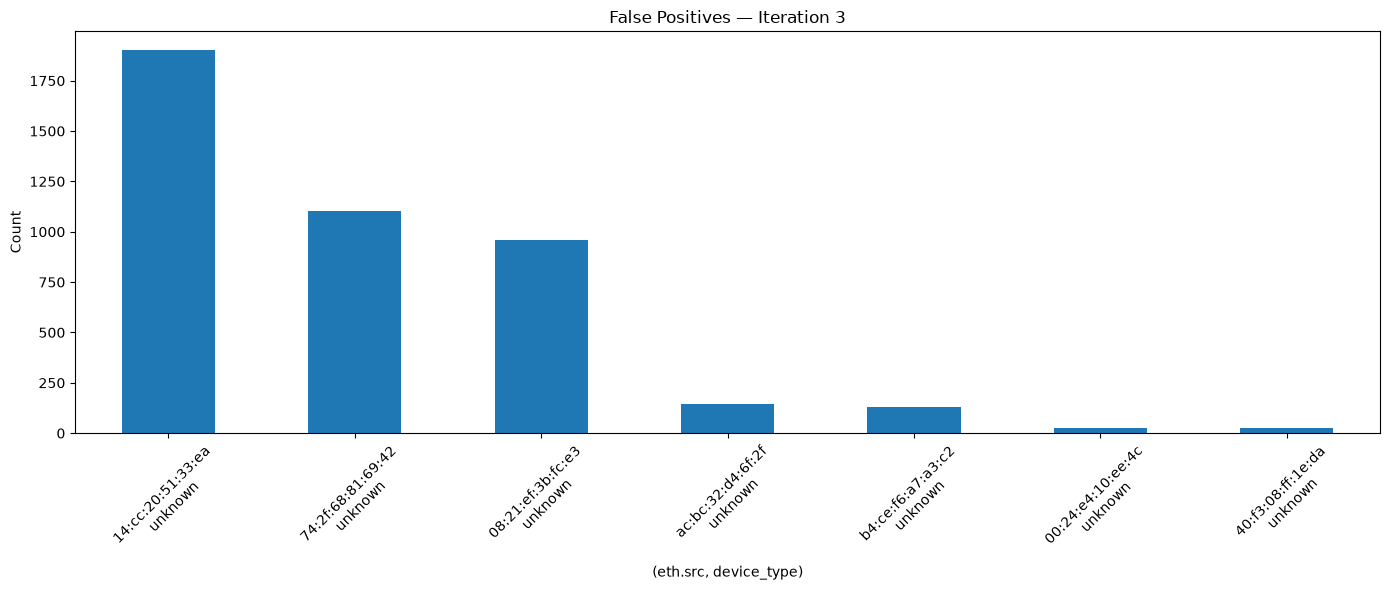

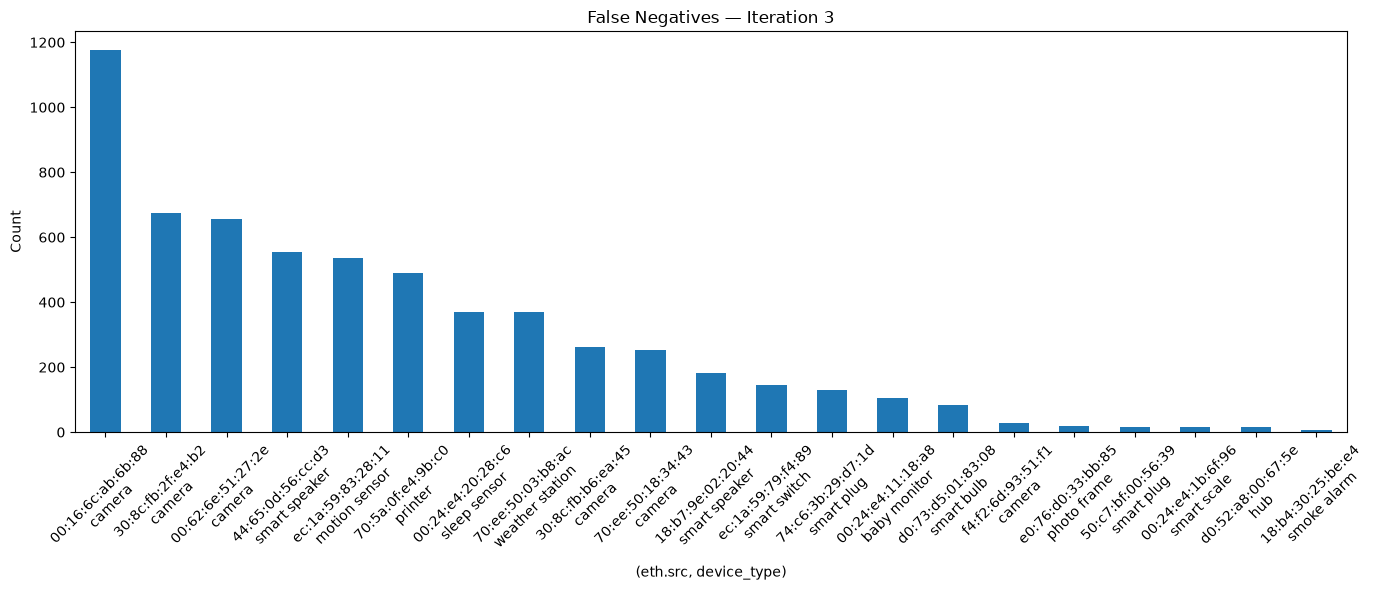

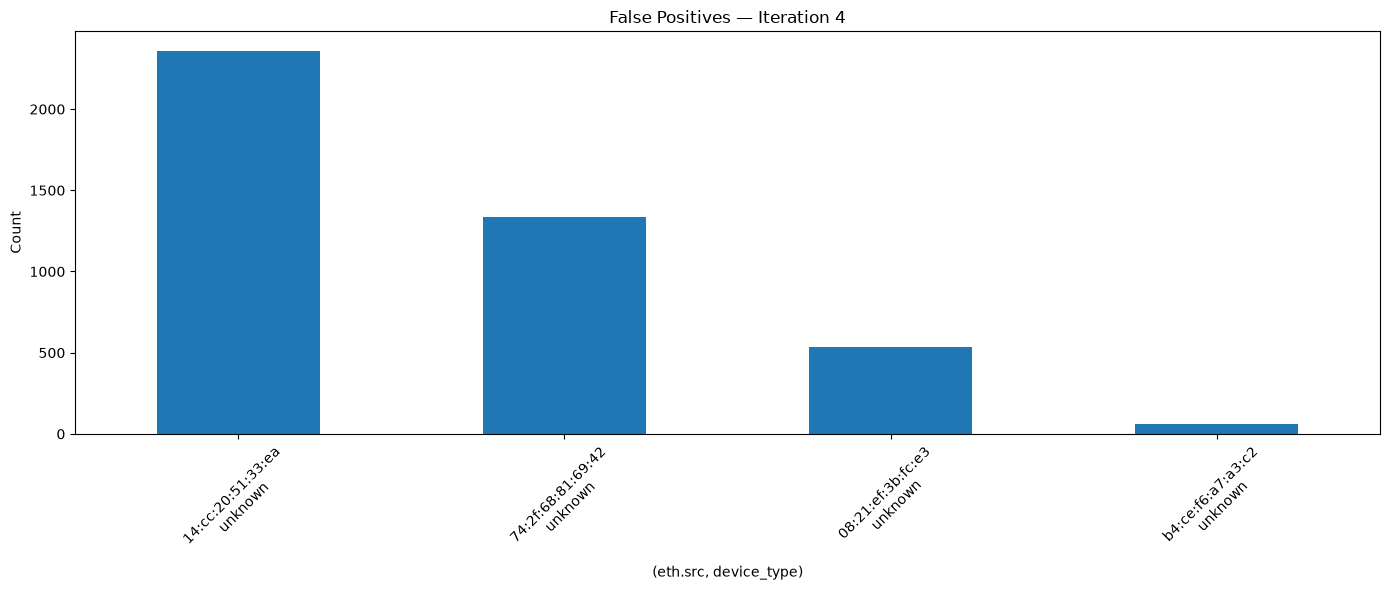

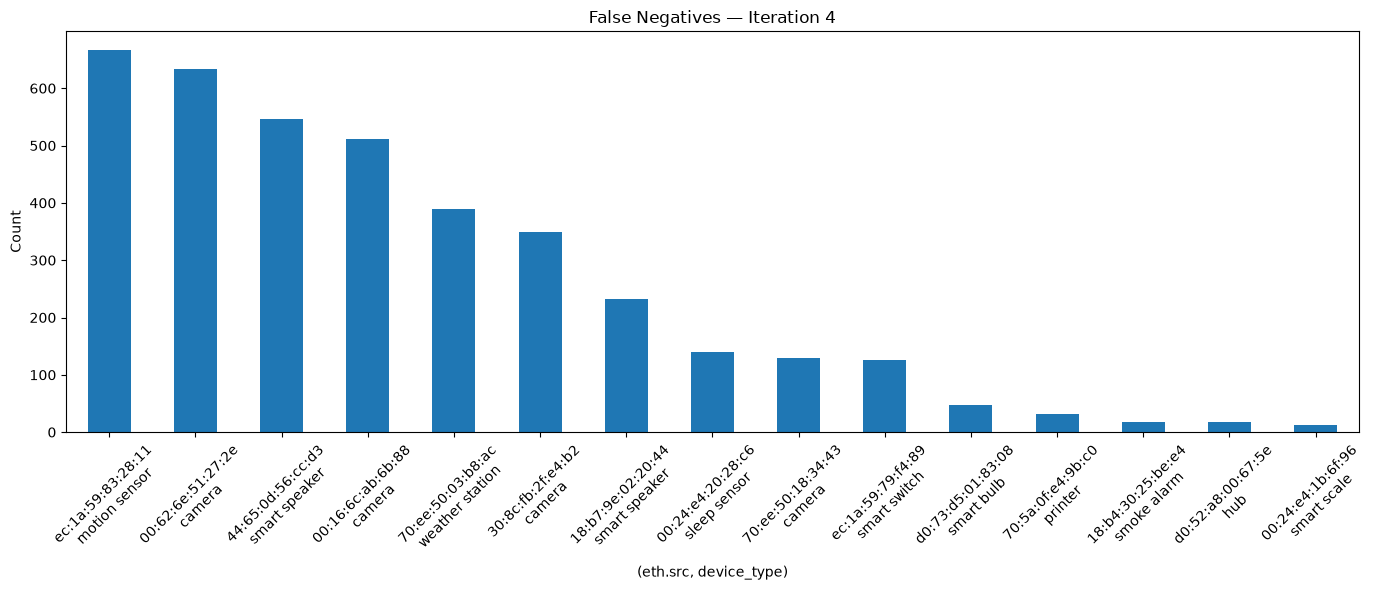

In [129]:
plot_errors_by_iteration(metric_df)

In [130]:
labeled_dataset.head(10)

,window,eth.src,packet_count,total_bytes,is_iot_device,device_type,vendor
1,0,14:cc:20:51:33:ea,21,1680,0,unknown,unknown
5,0,30:8c:fb:2f:e4:b2,5,780,1,camera,Dropcam
11,1,14:cc:20:51:33:ea,6,372,0,unknown,unknown
12,1,00:16:6c:ab:6b:88,38,14497,1,camera,Samsung
13,1,ec:1a:59:83:28:11,101,10097,1,motion sensor,Belkin
14,1,ec:1a:59:79:f4:89,85,23949,1,smart switch,Belkin
16,1,30:8c:fb:2f:e4:b2,4,624,1,camera,Dropcam
19,2,14:cc:20:51:33:ea,8,590,0,unknown,unknown
20,2,30:8c:fb:2f:e4:b2,4,534,1,camera,Dropcam
23,3,30:8c:fb:2f:e4:b2,5,780,1,camera,Dropcam


In [131]:
pair_count = (
    labeled_dataset
    .groupby(
        ["packet_count", "total_bytes", "is_iot_device"],
        as_index=False
    )
    .size()
    .rename(columns={"size": "count"})
)

pair_count = pair_count.sort_values(["packet_count", "total_bytes", "is_iot_device"], ascending=False)

In [132]:
pair_count

,packet_count,total_bytes,is_iot_device,count
110002,19533,29549722,0,1
110001,19154,2307940,0,1
110000,19050,28815690,0,1
109999,18085,2340669,0,1
109998,17812,26154242,0,1
...,...,...,...,...
4,4,172,1,1
3,4,172,0,6
2,4,169,1,1
1,4,168,1,264


In [133]:
conflicting_features = (
    labeled_dataset
    .groupby(["packet_count", "total_bytes"])
    .agg(
        label_count=("is_iot_device", "nunique"),
        sample_count=("is_iot_device", "size"),
        iot_count=("is_iot_device", lambda x: (x == 1).sum()),
        non_iot_count=("is_iot_device", lambda x: (x == 0).sum()),
    )
    .query("label_count > 1")
    .reset_index()
    .sort_values("sample_count", ascending=False)
)

In [134]:
agg = conflicting_features.groupby(["packet_count"]).agg(
    sample_count=("total_bytes", "size"),
    iot_count=("iot_count", "sum"),
    non_iot_count=("non_iot_count", "sum")
)

In [135]:
agg.head(50)

,sample_count,iot_count,non_iot_count
packet_count,,,
4,362,108060,3920
5,395,41505,4954
6,419,31965,7670
7,382,34047,10635
8,369,10605,10541
9,361,7367,10583
10,335,5108,8365
11,328,6591,6851
12,330,3778,6533


- What if we set a threshold to only consider window that has 9 or more packets in the window?
    - I've done it and it gives a worse accuracy